In [1]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from keras.layers import Dense, Flatten, Dropout
from keras.models import Sequential
from keras.optimizers import Adam

import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.plotting import plot_decision_regions

# Importing L1 and L2 regularizers

from keras.regularizers import l1, l2

In [3]:
from sklearn.datasets import make_moons

x, y = make_moons(100, noise = 0.25, random_state = 2)

In [4]:
x[0:10]

array([[ 1.04051282, -0.02334914],
       [-0.5547414 ,  1.27013832],
       [-0.07237151, -0.1779012 ],
       [-0.04719613,  1.21883595],
       [ 0.91379447,  0.85988324],
       [ 0.54115013,  0.69514025],
       [ 0.70302609, -0.25798507],
       [-0.13340109,  1.06959481],
       [-0.11428772,  0.89768827],
       [ 1.01150903,  0.84991658]])

In [5]:
y[0:10]

array([1, 0, 1, 0, 0, 0, 0, 0, 0, 0], dtype=int64)

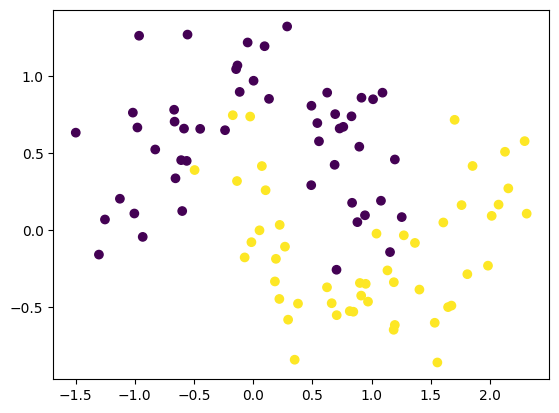

In [6]:
import matplotlib.pyplot as plt
plt.scatter(x[:,0], x[:,1], c=y)
plt.show()

# Without regularization

In [8]:
model1 = Sequential()

model1.add(Dense(128, input_dim = 2, activation = "relu"))
model1.add(Dense(128, activation="relu"))
model1.add(Dense(1, activation='sigmoid'))

model1.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_2 (Dense)             (None, 128)               384       
                                                                 
 dense_3 (Dense)             (None, 128)               16512     
                                                                 
 dense_4 (Dense)             (None, 1)                 129       
                                                                 
Total params: 17025 (66.50 KB)
Trainable params: 17025 (66.50 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [9]:
adam = Adam(learning_rate=0.01)

model1.compile(loss='binary_crossentropy', optimizer=adam, metrics=['accuracy'])

In [10]:
history1 = model1.fit(x, y, epochs=2000, validation_split = 0.2, verbose = 0)

# Give verbose = 0 to avoid displaying the progress of 2000 epochs

9600/9600 [==============================] - 14s 1ms/step


<AxesSubplot: >

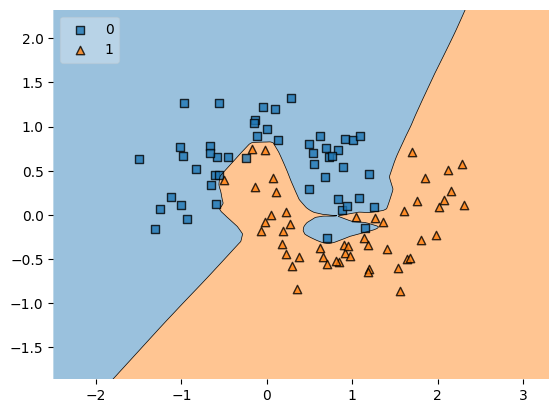

In [11]:
plot_decision_regions(x, y.astype('int'), clf = model1, legend = 2)

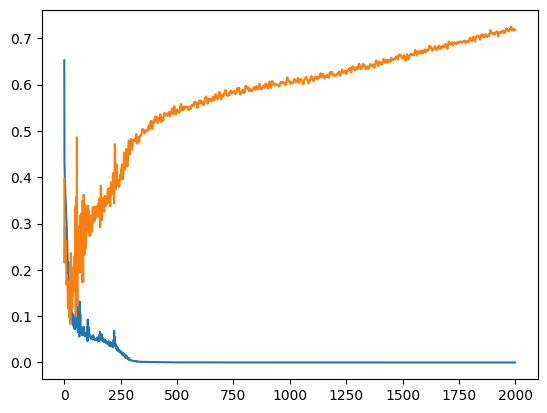

In [12]:
plt.plot(history1.history['loss'])
plt.plot(history1.history['val_loss'])

# With regularization

In [13]:
model2 = Sequential()

model2.add(Dense(128, activation = 'relu', input_dim = 2, kernel_regularizer = l2(0.001) ))
model2.add(Dense(128, activation="relu", kernel_regularizer = l2(0.001)))
model2.add(Dense(1,activation='sigmoid'))

model2.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_5 (Dense)             (None, 128)               384       
                                                                 
 dense_6 (Dense)             (None, 128)               16512     
                                                                 
 dense_7 (Dense)             (None, 1)                 129       
                                                                 
Total params: 17025 (66.50 KB)
Trainable params: 17025 (66.50 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [14]:
adam = Adam(learning_rate = 0.01)

model2.compile(loss = 'binary_crossentropy', optimizer = adam, metrics = ['accuracy'])

In [15]:
history2 = model2.fit(x, y, epochs = 2000, validation_split = 0.2, verbose = 0)

9600/9600 [==============================] - 15s 2ms/step


<AxesSubplot: >

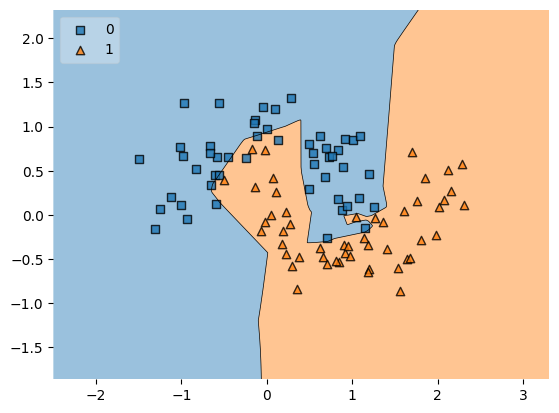

In [16]:
plot_decision_regions(x, y.astype('int'), clf = model2, legend=2)

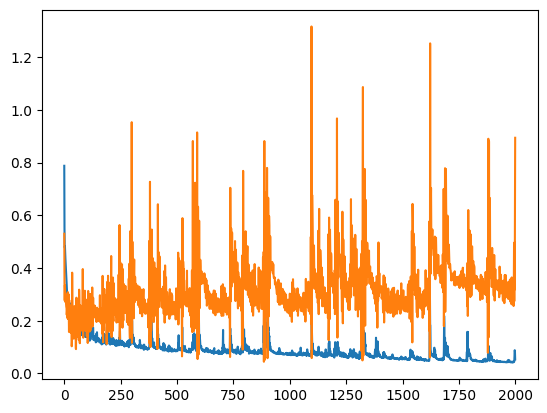

In [17]:
plt.plot(history2.history['loss'])
plt.plot(history2.history['val_loss'])

In [18]:
# We learnt that regularization reduces the weights near to zero. Now let's check this by
# making boxplot of weights of first layer for just checking

In [33]:
model1_weights = model1.get_weights()[0]

In [35]:
model1_weights.shape

(2, 128)

Text(0.5, 1.0, 'Model - 1. We can see the weights are ranging from almost -0.2 to 0.2')

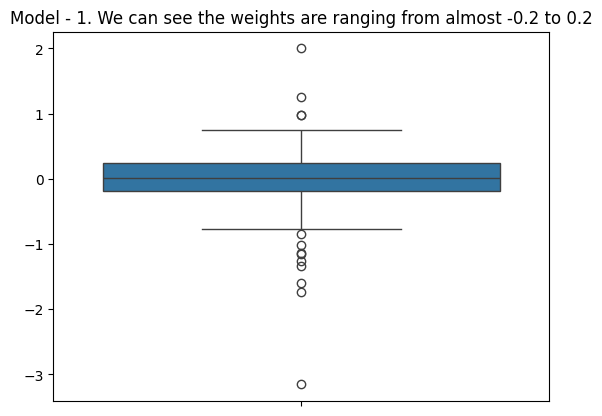

In [54]:
sns.boxplot(model1_weights.reshape(256))
plt.title("Model - 1. We can see the weights are ranging from almost -0.2 to 0.2")

In [47]:
model2_weights = model2.get_weights()[0]

Text(0.5, 1.0, 'Model - 2. We can see the weights are almost zero')

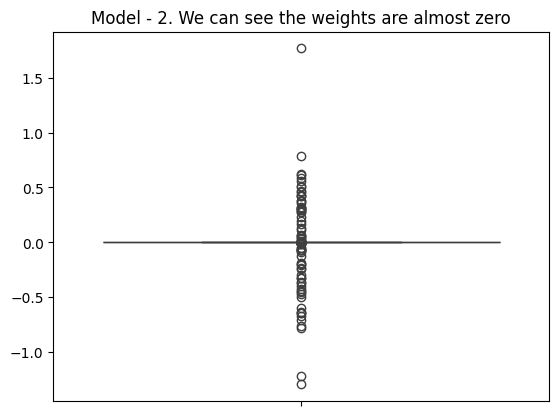

In [53]:
sns.boxplot(model2_weights.reshape(256))
plt.title('Model - 2. We can see the weights are almost zero')

# We can observe both the box plots and see that the majority values was between -0.3 and 0.3 in model without regularization
# and in model with regularization, majoority weights are almost zero

# Next, session 27 and 28 requires me to learn Algebra, derivatives and calculus. So I'm leaving that session and directly moving to Session 29.